# 🚀 Section 1: Deep Learning Environment & Global Configuration
---
### 📖 Introduction & Objectives
Welcome to the state-of-the-art **Arabic Automatic Speech Recognition (ASR)** pipeline. This project fine-tunes the pre-trained `openai/whisper-small` speech-to-text model on the highly curated `MBZUAI/ClArTTS` dataset. 

Whisper is a multi-lingual, multi-task transformer, but custom fine-tuning on regional dialects or specific datasets dramatically improves accuracy (lower Word Error Rate).

---
### 🛠️ Key Operations in this Section:
1. **Environment Initialization**: Install core deep learning packages (`transformers`, `datasets`, `librosa`, etc.).
2. **Hardware Diagnostics**: Verify CUDA compatibility, GPU device name, and available VRAM to ensure efficient FP16 execution.
3. **Global Configuration Setup**: Define the training hyper-parameters, checkpoint intervals, and storage directory inside a central `CONFIG` dictionary.

---
### 🎨 Premium Visualization Helper Function
We also define a custom aesthetic styling function `apply_premium_style()` to give all Matplotlib plots in this notebook a premium, modern design, sleek color palettes, and clear labels.


In [1]:
# SECTION 1: ENVIRONMENT SETUP
# ============================================================================

import os
import gc
import re
import time
import json
import random
import zipfile
import shutil

SAVE_DIR = '/kaggle/working/arabic_asr_whisper'
os.makedirs(SAVE_DIR, exist_ok=True)

!pip install -q torch torchaudio transformers datasets librosa jiwer evaluate accelerate soundfile

import torch
import numpy as np
import librosa
import evaluate
import matplotlib.pyplot as plt

# Define consistent, highly aesthetic, and premium matplotlib styles
def apply_premium_style():
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.rcParams['figure.facecolor'] = '#f8fafc' # Slate 50 (very clean, premium light grey)
    plt.rcParams['axes.facecolor'] = '#ffffff'
    plt.rcParams['axes.edgecolor'] = '#cbd5e1' # Slate 300
    plt.rcParams['axes.grid'] = True
    plt.rcParams['grid.color'] = '#f1f5f9' # Slate 100
    plt.rcParams['grid.linestyle'] = '-'
    plt.rcParams['grid.linewidth'] = 1.0
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Helvetica', 'Arial', 'Liberation Sans']
    plt.rcParams['axes.labelcolor'] = '#334155' # Slate 700
    plt.rcParams['text.color'] = '#1e293b' # Slate 800
    plt.rcParams['xtick.color'] = '#64748b' # Slate 500
    plt.rcParams['ytick.color'] = '#64748b'
    plt.rcParams['axes.titleweight'] = 'bold'
    plt.rcParams['axes.titlesize'] = 13
    plt.rcParams['axes.titlepad'] = 12
import matplotlib
matplotlib.rcParams['figure.dpi'] = 110

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"✅ GPU: {gpu_name} | VRAM: {vram_gb:.1f} GB")
    DEVICE = 'cuda'
else:
    print("⚠️ No GPU detected")
    DEVICE = 'cpu'

print(f"   PyTorch: {torch.__version__} | Device: {DEVICE}")

CONFIG = {
    'model_name': 'openai/whisper-small',
    'language': 'arabic',
    'task': 'transcribe',
    'target_sample_rate': 16000,
    'original_sample_rate': 40100,
    'dataset_name': 'MBZUAI/ClArTTS',
    'val_split': 0.10,
    'random_seed': 42,
    'epochs': 5,
    'batch_size': 4,          # REDUCED from 8 to 4
    'grad_accum': 4,          # INCREASED from 2 to 4 (effective batch = 16)
    'lr': 1e-5,
    'warmup_steps': 100,
    'eval_steps': 200,
    'save_steps': 200,
    'fp16': True,
    'ckpt_dir': '/kaggle/working/whisper-arabic-ckpts',
    'export_dir': '/kaggle/working/whisper-arabic-final',
    'save_dir': SAVE_DIR,
}

os.makedirs(CONFIG['ckpt_dir'], exist_ok=True)
os.makedirs(CONFIG['export_dir'], exist_ok=True)

print("\n✅ Configuration:")
for k, v in CONFIG.items():
    print(f"   {k:<22}: {v}")

# ============================================================================


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 48.1 MB/s eta 0:00:00
✅ GPU: Tesla T4 | VRAM: 15.6 GB
   PyTorch: 2.11.0+cu128 | Device: cuda

✅ Configuration:
   model_name            : openai/whisper-small
   language              : arabic
   task                  : transcribe
   target_sample_rate    : 16000
   original_sample_rate  : 40100
   dataset_name          : MBZUAI/ClArTTS
   val_split             : 0.1
   random_seed           : 42
   epochs                : 5
   batch_size            : 4
   grad_accum            : 4
   lr                    : 1e-05
   warmup_steps          : 100
   eval_steps            : 200
   save_steps            : 200
   fp16                  : True
   ckpt_dir              : /kaggle/working/whisper-arabic-ckpts
   export_dir            : /kaggle/working/whisper-arabic-final
   save_dir              : /kaggle/working/arabic_asr_whisper


# 📥 Section 2: Dataset Acquisition & Partitioning
---
### 📖 Dataset Overview
The `MBZUAI/ClArTTS` dataset is a high-quality Arabic Speech-to-Text dataset created by Mohamed bin Zayed University of Artificial Intelligence. It contains native Arabic speakers reading classical Arabic text.

---
### 🛠️ Key Operations:
1. **Download splits**: Fetch the official `train` and `test` shards directly from the Hugging Face Hub.
2. **Train/Validation Split**: Extract 10% of the training split to serve as our evaluation set (`validation`).
3. **Column Normalization**: Unify and standardize column names into a clean `['audio', 'sentence']` format to facilitate Whisper processing.
4. **Data Verification**: Inspect a raw sample's transcript, duration, and sampling rate to confirm data integrity.


In [2]:
# SECTION 2: LOAD DATASET
# ============================================================================

from datasets import load_dataset

print(f"\n📥 Loading {CONFIG['dataset_name']}...")

_train_full = load_dataset(CONFIG['dataset_name'], split='train')
_test = load_dataset(CONFIG['dataset_name'], split='test')

_split = _train_full.train_test_split(
    test_size=CONFIG['val_split'],
    seed=CONFIG['random_seed']
)

raw = {
    'train': _split['train'],
    'validation': _split['test'],
    'test': _test,
}

# Free original references
del _train_full, _split
gc.collect()

print("✅ Dataset loaded:")
for name, ds in raw.items():
    print(f"   {name:10s}: {len(ds):,} samples")

# 2.1 Inspect a Raw Sample
s = raw['train'][0]
print(f"\n🔍 Raw sample:")
print(f"   text         : {s['text'][:80]}...")
print(f"   sampling_rate: {s['sampling_rate']} Hz")
print(f"   duration     : {s['duration']:.2f}s")
print(f"   audio samples: {len(s['audio'])}")

# 2.2 Unify Column Names
def _keep(example):
    return {'audio': example['audio'], 'sentence': example['text']}

for split in raw:
    raw[split] = raw[split].map(
        _keep,
        remove_columns=raw[split].column_names,
        desc=f"Unifying [{split}]",
    )

print("\n✅ Columns unified:")
for name, ds in raw.items():
    print(f"   {name:10s}: {len(ds):,} · {ds.column_names}")

# ============================================================================



📥 Loading MBZUAI/ClArTTS...


README.md:   0%|          | 0.00/2.21k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

data/train-00000-of-00026.parquet: reconstructing file:   0%|          |  0.00B /  123MB            

...

✅ Dataset loaded:
   train     : 8,550 samples
   validation: 950 samples
   test      : 205 samples

🔍 Raw sample:
   text         : مَقَامُ شَاهِدٍ عَدْلٍ غَيْرِ مُتَّهَمِ...
   sampling_rate: 40100 Hz
   duration     : 3.80s
   audio samples: 152463


Unifying [train]:   0%|          | 0/8550 [00:00<?, ? examples/s]

Unifying [validation]:   0%|          | 0/950 [00:00<?, ? examples/s]

Unifying [test]:   0%|          | 0/205 [00:00<?, ? examples/s]


✅ Columns unified:
   train     : 8,550 · ['audio', 'sentence']
   validation: 950 · ['audio', 'sentence']
   test      : 205 · ['audio', 'sentence']


# 🎙️ Section 3: High-Fidelity Audio Preprocessing Pipeline
---
### 📖 The Need for Resampling and Preprocessing
The Whisper model expects mono-channel audio sampled at exactly **16,000 Hz**. However, the raw `ClArTTS` dataset is recorded at **40,100 Hz**. Processing mismatch will cause incorrect feature maps.

---
### 🛠️ Preprocessing Workflow:
1. **Stereo to Mono**: Average stereo channels to a single mono-channel waveform.
2. **Resampling**: Downsample audio from 40.1 kHz to 16 kHz using high-quality windowed sinc interpolation in `librosa`.
3. **Silence Trimming**: Remove leading and trailing silence zones (using a 20dB threshold) to prevent model learning empty frames.
4. **Peak Normalization**: Normalize peak amplitude to `0.9` to optimize loudness balance and ensure stability across batch training.
5. **Interactive Visualization**: Generate a premium, high-resolution comparison chart showing the raw waveform vs. the clean, preprocessed waveform.



✅ Audio preprocessing OK
   152463 @ 40100Hz → 56320 @ 16000Hz


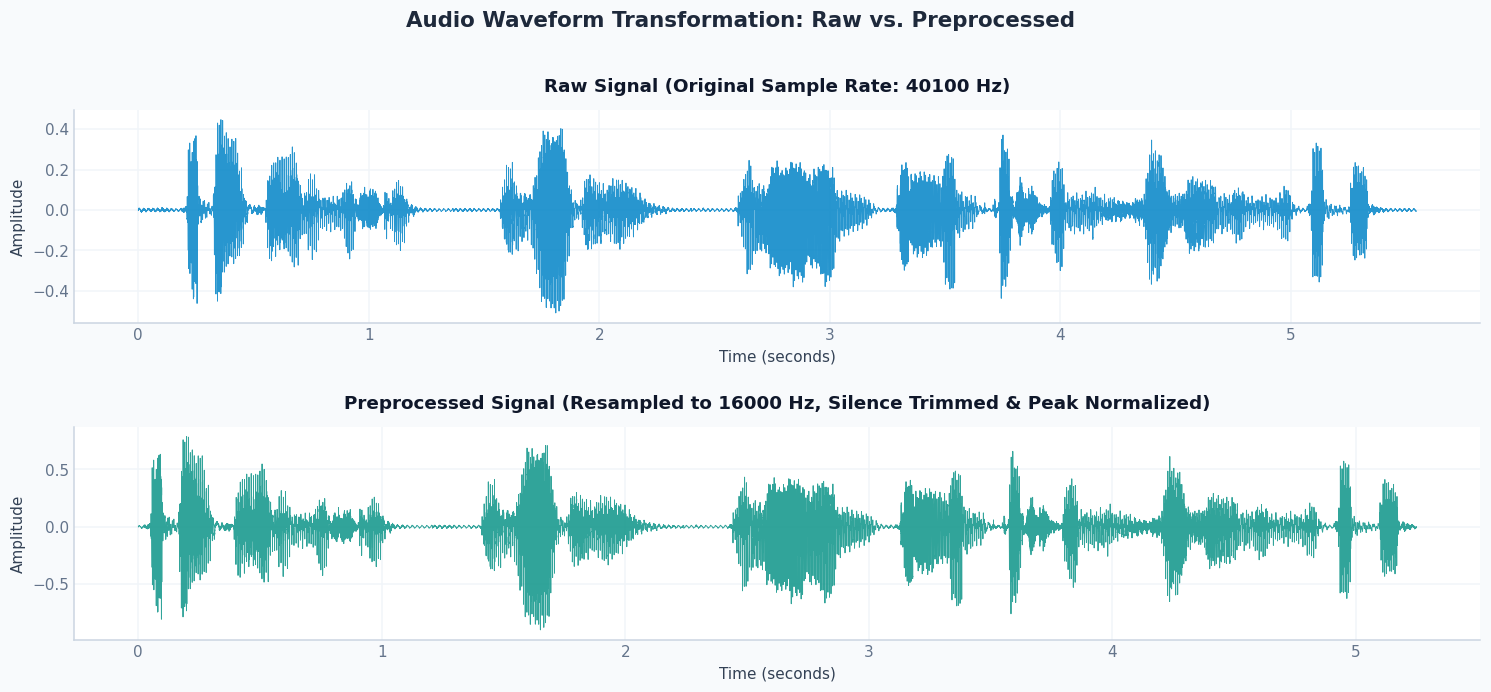

✅ Waveform plot saved.


In [3]:
# SECTION 3: AUDIO PREPROCESSING
# ============================================================================

def to_mono(wave):
    if wave.ndim == 2:
        wave = wave.mean(axis=0)
    return wave.astype(np.float32)

def resample_audio(wave, orig_sr, target_sr):
    if orig_sr != target_sr:
        wave = librosa.resample(wave, orig_sr=orig_sr, target_sr=target_sr)
    return wave.astype(np.float32)

def trim_silence(wave, top_db=20):
    trimmed, _ = librosa.effects.trim(wave, top_db=top_db)
    return trimmed

def normalize_loudness(wave, peak=0.9):
    max_amp = np.abs(wave).max()
    if max_amp > 1e-8:
        wave = wave * (peak / max_amp)
    return wave

def preprocess_audio(wave, orig_sr, target_sr, do_trim=True, do_normalize=True):
    wave = to_mono(wave)
    wave = resample_audio(wave, orig_sr, target_sr)
    if do_trim:
        wave = trim_silence(wave)
    if do_normalize:
        wave = normalize_loudness(wave)
    return wave

# Smoke test
_tw = np.array(raw['train'][0]['audio']).astype(np.float32)
_pw = preprocess_audio(_tw, CONFIG['original_sample_rate'], CONFIG['target_sample_rate'])
print(f"\n✅ Audio preprocessing OK")
print(f"   {len(_tw)} @ {CONFIG['original_sample_rate']}Hz → {len(_pw)} @ {CONFIG['target_sample_rate']}Hz")
del _tw, _pw
gc.collect()

# 3.1 Waveform Visualization
_idx = 2
_raw_wave = np.array(raw['train'][_idx]['audio']).astype(np.float32)
_proc_wave = preprocess_audio(
    _raw_wave, CONFIG['original_sample_rate'], CONFIG['target_sample_rate']
)

t_raw = np.linspace(0, len(_raw_wave) / CONFIG['original_sample_rate'], len(_raw_wave))
t_proc = np.linspace(0, len(_proc_wave) / CONFIG['target_sample_rate'], len(_proc_wave))

apply_premium_style()
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=False)
axes[0].plot(t_raw, _raw_wave, color='#0284c7', lw=0.6, alpha=0.85)
axes[0].set_title(f'Raw Signal (Original Sample Rate: {CONFIG["original_sample_rate"]} Hz)', fontsize=12, fontweight='bold', color='#0f172a')
axes[0].set_ylabel('Amplitude', fontsize=10)
axes[0].set_xlabel('Time (seconds)', fontsize=10)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

axes[1].plot(t_proc, _proc_wave, color='#0d9488', lw=0.6, alpha=0.85)
axes[1].set_title(f'Preprocessed Signal (Resampled to {CONFIG["target_sample_rate"]} Hz, Silence Trimmed & Peak Normalized)', fontsize=12, fontweight='bold', color='#0f172a')
axes[1].set_ylabel('Amplitude', fontsize=10)
axes[1].set_xlabel('Time (seconds)', fontsize=10)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

fig.suptitle('Audio Waveform Transformation: Raw vs. Preprocessed', fontsize=14, fontweight='bold', color='#1e293b', y=0.98)
plt.tight_layout(pad=2.0)
plt.savefig(f"{CONFIG['save_dir']}/waveform_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
del _raw_wave, _proc_wave, t_raw, t_proc
gc.collect()
print("✅ Waveform plot saved.")


# 📝 Section 4: Arabic Text Standardization & Normalization
---
### 📖 Orthographic Challenges in Arabic
Arabic speech recognition requires standardizing transcript annotations because Classic Arabic is rich with optional diacritics (Harakat) and orthographic letters that sound identical in speech (e.g. various Hamza shapes). Removing or standardizing these ensures high model convergence and realistic Evaluation Metrics.

---
### 🛠️ Normalization Strategy:
1. **Diacritics Removal (Tashkeel)**: Remove optional vowels (Fatha, Damma, Kasra, Shadda, etc.).
2. **Alif/Ya Standardization**: Standardize variants of Alif (`أإآٱ` to `ا`), Ta Marbuta (`ة` to `ه`), and Ya (`ى` to `ي`).
3. **Punctuation Clean-up**: Remove punctuation marks and extra whitespace to build clean sequence target labels.


In [4]:
# SECTION 4: ARABIC TEXT NORMALIZATION
# ============================================================================

_DIACRITICS = re.compile(r'[\u064B-\u065F\u0670]')
_PUNCTUATION = re.compile(
    r'[\u060C\u061B\u061F\u06D4'
    r'!\"\'\(\)\[\]\{\}\.\,'
    r'\:\;\-\_\?\@\#\$\%\^\&\*\/\\]'
)

def remove_diacritics(text):
    return _DIACRITICS.sub('', text)

def normalize_chars(text):
    text = re.sub(r'[أإآٱ]', 'ا', text)
    text = re.sub(r'ة', 'ه', text)
    text = re.sub(r'ى', 'ي', text)
    return text

def remove_punctuation(text):
    return _PUNCTUATION.sub('', text)

def normalize_arabic(text):
    if not text:
        return ""
    text = remove_diacritics(text)
    text = normalize_chars(text)
    text = remove_punctuation(text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

_tests = [
    ('كِتَابٌ جَمِيلٌ', 'diacritics'),
    ('أَهْلاً وَسَهْلاً', 'hamza+diacritics'),
    ('الجامعةُ العربيةُ.', 'ta marbuta+punct'),
    ('إِنَّ الله مَعَنَا', 'hamza+diacritics'),
]

print("\n✅ Arabic normalization tests:")
for raw_text, label in _tests:
    print(f"  [{label}] {raw_text} → {normalize_arabic(raw_text)}")

# ============================================================================



✅ Arabic normalization tests:
  [diacritics] كِتَابٌ جَمِيلٌ → كتاب جميل
  [hamza+diacritics] أَهْلاً وَسَهْلاً → اهلا وسهلا
  [ta marbuta+punct] الجامعةُ العربيةُ. → الجامعه العربيه
  [hamza+diacritics] إِنَّ الله مَعَنَا → ان الله معنا


# 🔍 Section 5: Whisper Processor & Feature Extractor Initialization
---
### 📖 Connecting Audio to Transformers
To feed audio into the Whisper Transformer, we use the `WhisperProcessor` which encapsulates two distinct helpers:
1. **WhisperFeatureExtractor**: Converts raw 1D time-series audio waveforms into 2D Log-Mel spectrogram matrices (using 80 frequency filterbanks).
2. **WhisperTokenizer**: Standardizes the target vocabulary, translating Arabic letters into discrete Token IDs.

We visualize the resulting **Log-Mel Spectrogram** using a beautiful colormap to understand how the audio energy changes over time and frequencies.



📥 Loading Whisper components: openai/whisper-small


preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

...

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

✅ Loaded | SR: 16000Hz | Mel: 80 | Vocab: 50,258

📊 Mel shape: (80, 3000)


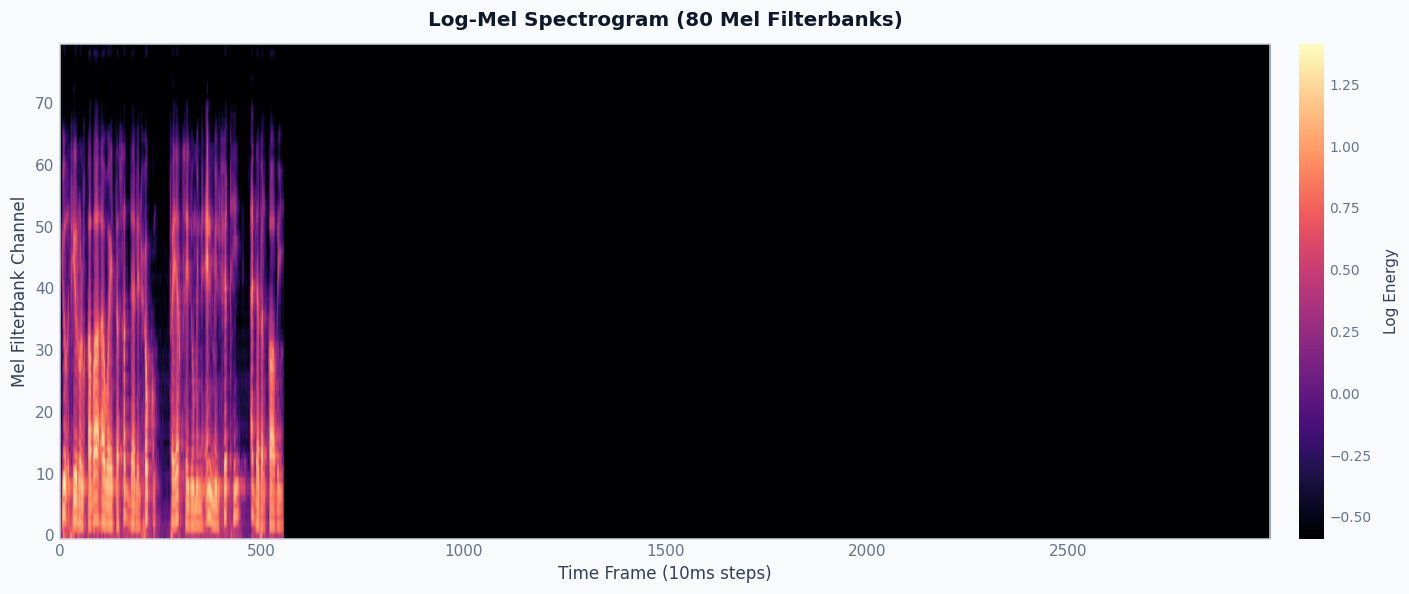

124

In [5]:
# SECTION 5: LOAD WHISPER COMPONENTS
# ============================================================================

from transformers import WhisperFeatureExtractor, WhisperTokenizer, WhisperProcessor

print(f"\n📥 Loading Whisper components: {CONFIG['model_name']}")

feature_extractor = WhisperFeatureExtractor.from_pretrained(CONFIG['model_name'])
tokenizer = WhisperTokenizer.from_pretrained(
    CONFIG['model_name'], language=CONFIG['language'], task=CONFIG['task']
)
processor = WhisperProcessor.from_pretrained(
    CONFIG['model_name'], language=CONFIG['language'], task=CONFIG['task']
)

print(f"✅ Loaded | SR: {feature_extractor.sampling_rate}Hz | "
      f"Mel: {feature_extractor.feature_size} | Vocab: {tokenizer.vocab_size:,}")

# 5.1 Mel Spectrogram Visualization
_wave = preprocess_audio(
    np.array(raw['train'][3]['audio']).astype(np.float32),
    CONFIG['original_sample_rate'], CONFIG['target_sample_rate']
)
_mel = feature_extractor(
    _wave, sampling_rate=CONFIG['target_sample_rate'], return_tensors='np'
).input_features[0]

print(f"\n📊 Mel shape: {_mel.shape}")

apply_premium_style()
fig, ax = plt.subplots(figsize=(14, 5.5))
im = ax.imshow(_mel, aspect='auto', origin='lower', cmap='magma')
ax.grid(False)
ax.set_title("Log-Mel Spectrogram (80 Mel Filterbanks)", fontsize=13, fontweight='bold', color='#0f172a', pad=12)
ax.set_xlabel('Time Frame (10ms steps)', fontsize=11, color='#334155')
ax.set_ylabel('Mel Filterbank Channel', fontsize=11, color='#334155')

cbar = fig.colorbar(im, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Log Energy', fontsize=10, color='#334155', labelpad=8)
cbar.ax.tick_params(labelsize=9)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.savefig(f"{CONFIG['save_dir']}/mel_spectrogram.png", dpi=150, bbox_inches='tight')
plt.show()
del _wave, _mel
gc.collect()


# 💾 Section 6: Memory-Safe Feature Extraction (Disk Caching)
---
### ⚠️ Mitigating RAM Out-Of-Memory (OOM) Crashes
Converting entire audio datasets into massive 2D Log-Mel spectrogram matrices inside system RAM frequently crashes Jupyter kernels (Kaggle/Colab notebooks limit RAM to ~16GB or 30GB).

### 🛠️ The Solution: Chunked Processing
We divide the dataset into small chunks (**500 samples each**), process them sequentially, and immediately serialize the results to Apache Arrow files on disk. The Hugging Face `Datasets` library will read cache files on-demand without memory leakages.


In [6]:
# SECTION 6: PREPARE DATASET — MEMORY-SAFE (SAVE TO DISK)
# ============================================================================
# 
# KEY FIX: Instead of storing all spectrograms in RAM (causes OOM),
# we process in small chunks and let HuggingFace Datasets save to 
# Apache Arrow files on disk using keep_in_memory=False.
#

def prepare_single(example):
    """Process one sample: audio → mel, text → token IDs."""
    wave = np.array(example['audio']).astype(np.float32)
    wave = preprocess_audio(
        wave,
        orig_sr=CONFIG['original_sample_rate'],
        target_sr=CONFIG['target_sample_rate']
    )

    mel = feature_extractor(
        wave, sampling_rate=CONFIG['target_sample_rate'], return_tensors='np'
    ).input_features[0]

    norm_text = normalize_arabic(example['sentence'])
    token_ids = tokenizer(norm_text, return_tensors='np').input_ids[0]

    return {
        'input_features': mel,
        'labels': token_ids.tolist(),  # list for Arrow serialization
    }


# Smoke test
_out = prepare_single(raw['train'][0])
print(f"\n✅ prepare_single() test:")
print(f"   mel shape: {np.array(_out['input_features']).shape}")
print(f"   labels[:8]: {_out['labels'][:8]}")
print(f"   decoded: {tokenizer.decode(_out['labels'], skip_special_tokens=True)}")


# --- Process all splits with CHUNKED processing to avoid OOM ---

CHUNK_SIZE = 500  # Process 500 samples at a time, write to disk, free RAM

def process_split_chunked(dataset, split_name):
    """
    Process a split in chunks to avoid RAM overflow.
    Each chunk is processed, then the dataset library handles disk caching.
    """
    from datasets import Dataset, concatenate_datasets

    total = len(dataset)
    num_chunks = (total + CHUNK_SIZE - 1) // CHUNK_SIZE
    chunk_datasets = []

    print(f"\n   Processing '{split_name}': {total:,} samples in {num_chunks} chunks of {CHUNK_SIZE}")
    t0 = time.time()

    for chunk_idx in range(num_chunks):
        start = chunk_idx * CHUNK_SIZE
        end = min(start + CHUNK_SIZE, total)

        all_features = []
        all_labels = []

        for i in range(start, end):
            ex = dataset[i]
            wave = np.array(ex['audio']).astype(np.float32)
            wave = preprocess_audio(
                wave,
                orig_sr=CONFIG['original_sample_rate'],
                target_sr=CONFIG['target_sample_rate']
            )

            mel = feature_extractor(
                wave,
                sampling_rate=CONFIG['target_sample_rate'],
                return_tensors='np'
            ).input_features[0]

            norm_text = normalize_arabic(ex['sentence'])
            token_ids = tokenizer(norm_text, return_tensors='np').input_ids[0]

            all_features.append(mel)
            all_labels.append(token_ids.tolist())

        # Create a small dataset from this chunk
        chunk_ds = Dataset.from_dict({
            'input_features': all_features,
            'labels': all_labels,
        })
        chunk_datasets.append(chunk_ds)

        # FREE this chunk's data from RAM
        del all_features, all_labels
        gc.collect()

        elapsed = time.time() - t0
        rate = end / elapsed if elapsed > 0 else 0
        eta = (total - end) / rate if rate > 0 else 0
        print(f"      Chunk {chunk_idx+1}/{num_chunks} | "
              f"{end:,}/{total:,} | "
              f"{rate:.1f} samples/s | "
              f"ETA: {eta:.0f}s")

    # Concatenate all chunks into one dataset (disk-backed)
    print(f"   Concatenating {len(chunk_datasets)} chunks...")
    final_ds = concatenate_datasets(chunk_datasets)

    # Free chunk references
    del chunk_datasets
    gc.collect()

    total_time = time.time() - t0
    print(f"   ✅ '{split_name}' done: {len(final_ds):,} samples in {total_time:.0f}s")

    return final_ds


print("\n" + "=" * 70)
print("⚙️  PROCESSING ALL SPLITS (CHUNKED — MEMORY-SAFE)")
print("=" * 70)

pipeline_start = time.time()
processed = {}

for split_name in ['train', 'validation', 'test']:
    print(f"\n{'─'*60}")
    print(f"📊 '{split_name}' ({len(raw[split_name]):,} samples)")
    print(f"{'─'*60}")

    processed[split_name] = process_split_chunked(raw[split_name], split_name)

    # Force garbage collection after each split
    gc.collect()
    torch.cuda.empty_cache()

pipeline_time = time.time() - pipeline_start

print("\n" + "=" * 70)
print("✅ ALL SPLITS PROCESSED")
print("=" * 70)
print(f"   Train      : {len(processed['train']):,}")
print(f"   Validation : {len(processed['validation']):,}")
print(f"   Test       : {len(processed['test']):,}")
print(f"   Total time : {pipeline_time:.0f}s ({pipeline_time/60:.1f} min)")

# Verify
_v = processed['train'][0]
print(f"\n🔍 Verify first sample:")
print(f"   mel shape : {np.array(_v['input_features']).shape}")
print(f"   labels[:8]: {_v['labels'][:8]}")
print(f"   decoded   : {tokenizer.decode(_v['labels'], skip_special_tokens=True)}")

# ============================================================================


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.



✅ prepare_single() test:
   mel shape: (80, 3000)
   labels[:8]: [50258, 50272, 50359, 50363, 2304, 4587, 10943, 13412]
   decoded: مقام شاهد عدل غير متهم

⚙️  PROCESSING ALL SPLITS (CHUNKED — MEMORY-SAFE)

────────────────────────────────────────────────────────────
📊 'train' (8,550 samples)
────────────────────────────────────────────────────────────

   Processing 'train': 8,550 samples in 18 chunks of 500
      Chunk 1/18 | 500/8,550 | 10.5 samples/s | ETA: 764s
      Chunk 2/18 | 1,000/8,550 | 10.5 samples/s | ETA: 721s
      Chunk 3/18 | 1,500/8,550 | 10.4 samples/s | ETA: 677s
      Chunk 4/18 | 2,000/8,550 | 10.3 samples/s | ETA: 633s
      Chunk 5/18 | 2,500/8,550 | 10.3 samples/s | ETA: 589s
      Chunk 6/18 | 3,000/8,550 | 10.3 samples/s | ETA: 539s
      Chunk 7/18 | 3,500/8,550 | 10.3 samples/s | ETA: 491s
      Chunk 8/18 | 4,000/8,550 | 10.3 samples/s | ETA: 442s
      Chunk 9/18 | 4,500/8,550 | 10.3 samples/s | ETA: 393s
      Chunk 10/18 | 5,000/8,550 | 10.3 samples/s

# 🧹 Section 7: RAM Optimization & Cache Flushing
---
We now discard the raw audio references from system memory and call Python's Garbage Collector (`gc`) and PyTorch's CUDA cache flusher. This releases all system and GPU memory, leaving maximum headroom for the model weights during training.


In [7]:
# SECTION 7: FREE RAW DATASET FROM RAM
# ============================================================================

# Critical: raw dataset holds ALL audio arrays in memory
# We no longer need them after processing

# Keep a small reference for inference later
raw_test_backup = raw['test']

del raw
gc.collect()
torch.cuda.empty_cache()

print("\n✅ Raw dataset freed from RAM")
print(f"   Kept raw_test_backup: {len(raw_test_backup):,} samples for inference")

# ============================================================================



✅ Raw dataset freed from RAM
   Kept raw_test_backup: 205 samples for inference


# 🤖 Section 8: Initialize Pre-trained Whisper Model
---
### 📖 Model Architecture
We load the pre-trained `openai/whisper-small` model weights, ensuring the generation configuration points specifically to `arabic` and the `transcribe` task. We move the model to the GPU for hardware-accelerated backpropagation.


In [8]:
# SECTION 8: LOAD MODEL
# ============================================================================

from transformers import WhisperForConditionalGeneration

print(f"\n📥 Loading model: {CONFIG['model_name']}")

model = WhisperForConditionalGeneration.from_pretrained(CONFIG['model_name'])
model.generation_config.language = CONFIG['language']
model.generation_config.task = CONFIG['task']
model.generation_config.forced_decoder_ids = None
model.config.forced_decoder_ids = None

model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"✅ Model on {DEVICE}")
print(f"   Total params    : {total_params:,}")
print(f"   Trainable params: {trainable_params:,}")

FREEZE_ENCODER = False
if FREEZE_ENCODER:
    for param in model.model.encoder.parameters():
        param.requires_grad = False
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"❄️ Encoder frozen | Trainable: {trainable:,}")
else:
    print(f"✅ Full fine-tuning: {trainable_params:,} params")

# ============================================================================



📥 Loading model: openai/whisper-small


model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.87k [00:00<?, ?B/s]

✅ Model on cuda
   Total params    : 241,734,912
   Trainable params: 241,734,912
✅ Full fine-tuning: 241,734,912 params


# ⚙️ Section 9: Trainer Configuration & Error Metric Setup
---
### 📖 Evaluation Metrics (WER & CER)
ASR models are evaluated using two standard indicators:
1. **Word Error Rate (WER)**: The percentage of words that are inserted, deleted, or substituted in the prediction.
2. **Character Error Rate (CER)**: Similar to WER but measured at the individual character level (highly suited for phonetic spelling verification).

We setup the Seq2Seq training parameters (FP16 mixed-precision, gradient accumulation, learning rate scheduling) and instantiate the HuggingFace `Seq2SeqTrainer`.


In [9]:
# SECTION 9: TRAINING SETUP
# ============================================================================

from dataclasses import dataclass
from typing import Any, Dict, List, Union
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer


@dataclass
class WhisperDataCollator:
    processor: Any

    def __call__(self, features: List[Dict[str, Union[List[int], torch.Tensor]]]) -> Dict[str, torch.Tensor]:
        audio_feats = [{'input_features': f['input_features']} for f in features]
        batch = self.processor.feature_extractor.pad(audio_feats, return_tensors='pt')

        label_feats = [{'input_ids': f['labels']} for f in features]
        labels_batch = self.processor.tokenizer.pad(label_feats, return_tensors='pt')

        labels = labels_batch['input_ids'].masked_fill(
            labels_batch.attention_mask.ne(1), -100
        )

        if (labels[:, 0] == self.processor.tokenizer.bos_token_id).all():
            labels = labels[:, 1:]

        batch['labels'] = labels
        return batch


collator = WhisperDataCollator(processor=processor)

# Metrics
_wer_metric = evaluate.load('wer')
_cer_metric = evaluate.load('cer')

def compute_metrics(pred):
    pred_ids = pred.predictions
    label_ids = pred.label_ids

    if isinstance(pred_ids, tuple):
        pred_ids = pred_ids[0]

    label_ids = np.where(label_ids == -100, tokenizer.pad_token_id, label_ids)

    pred_str = [normalize_arabic(t) for t in tokenizer.batch_decode(pred_ids, skip_special_tokens=True)]
    label_str = [normalize_arabic(t) for t in tokenizer.batch_decode(label_ids, skip_special_tokens=True)]

    pairs = [(p, r) for p, r in zip(pred_str, label_str) if r.strip()]
    if not pairs:
        return {'wer': 100.0, 'cer': 100.0}

    preds = [p for p, _ in pairs]
    refs = [r for _, r in pairs]

    wer = _wer_metric.compute(predictions=preds, references=refs)
    cer = _cer_metric.compute(predictions=preds, references=refs)

    return {'wer': round(wer * 100, 2), 'cer': round(cer * 100, 2)}


# Training arguments
training_args = Seq2SeqTrainingArguments(
    output_dir=CONFIG['ckpt_dir'],
    num_train_epochs=CONFIG['epochs'],
    per_device_train_batch_size=CONFIG['batch_size'],
    per_device_eval_batch_size=CONFIG['batch_size'],
    gradient_accumulation_steps=CONFIG['grad_accum'],
    learning_rate=CONFIG['lr'],
    warmup_steps=CONFIG['warmup_steps'],
    fp16=CONFIG['fp16'],
    eval_strategy='steps',
    eval_steps=CONFIG['eval_steps'],
    save_strategy='steps',
    save_steps=CONFIG['save_steps'],
    load_best_model_at_end=True,
    metric_for_best_model='wer',
    greater_is_better=False,
    save_total_limit=2,
    predict_with_generate=True,
    generation_max_length=225,
    logging_steps=50,
    report_to=[],
    push_to_hub=False,
    remove_unused_columns=False,
    dataloader_num_workers=2,
    dataloader_pin_memory=False,  # Save RAM
)

eff_batch = CONFIG['batch_size'] * CONFIG['grad_accum']
steps_per_epoch = len(processed['train']) // eff_batch

print(f"\n✅ Training config:")
print(f"   Batch: {CONFIG['batch_size']} × {CONFIG['grad_accum']} = {eff_batch} effective")
print(f"   Steps/epoch: ~{steps_per_epoch}")
print(f"   Total steps: ~{steps_per_epoch * CONFIG['epochs']}")

# Trainer
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=processed['train'],
    eval_dataset=processed['validation'],
    data_collator=collator,
    compute_metrics=compute_metrics,
)

print(f"✅ Trainer ready | Train: {len(processed['train']):,} | Val: {len(processed['validation']):,}")

# ============================================================================



✅ Training config:
   Batch: 4 × 4 = 16 effective
   Steps/epoch: ~534
   Total steps: ~2670
✅ Trainer ready | Train: 8,550 | Val: 950


# 🚀 Section 10: Model Training & Fine-Tuning Execution
---
Let's fire up the training loop! The trainer will output training loss, evaluation loss, WER, and CER at intervals of 200 steps. A model checkpoint will be saved to disk whenever validation performance improves.


In [10]:
# SECTION 10: TRAINING
# ============================================================================

gc.collect()
torch.cuda.empty_cache()

print("\n🚀 Starting fine-tuning...")
print("   Monitor 'eval/wer' — lower is better.\n")

result = trainer.train()

print(f"\n✅ Training complete!")
print(f"   Runtime: {result.metrics['train_runtime']:.0f}s")
print(f"   Samples/s: {result.metrics['train_samples_per_second']:.1f}")
print(f"   Final loss: {result.metrics['train_loss']:.4f}")

# ============================================================================



🚀 Starting fine-tuning...
   Monitor 'eval/wer' — lower is better.



/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss,Validation Loss,Wer,Cer
200,1.610134,0.184806,15.060000,3.860000
400,0.844481,0.153976,12.440000,3.210000
600,0.345026,0.140774,10.960000,2.770000
800,0.393232,0.136861,10.370000,2.670000
1000,0.156395,0.139701,10.140000,2.610000
1200,0.092360,0.144676,10.100000,2.610000
1340,0.084116,0.143879,10.130000,2.620000


[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] The attention mask is not set with a batched input, and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['proj_out.weight'].



✅ Training complete!
   Runtime: 16052s
   Samples/s: 2.7
   Final loss: 1.3592


# 📊 Section 11: Quantitative & Qualitative Evaluation
---
### 📖 Generalization Diagnostics
We run the final fine-tuned model weights against our unseen `test` dataset split. We report overall test loss, WER, and CER. We also sample **8 random test utterances** to compare Ground Truth (REF) vs. Model Prediction (PRED) for qualitative audit.


In [11]:
# SECTION 11: EVALUATION
# ============================================================================

forced_decoder_ids = processor.get_decoder_prompt_ids(
    language=CONFIG['language'], task=CONFIG['task']
)
model.generation_config.forced_decoder_ids = forced_decoder_ids

print("\n📊 Evaluating on test set...")

eval_results = trainer.evaluate(
    eval_dataset=processed['test'],
    metric_key_prefix='test',
    max_length=225,
    num_beams=5,
)

print("\n✅ Test Results:")
print("─" * 45)
for k, v in eval_results.items():
    if isinstance(v, float):
        print(f"   {k:<30}: {v:.4f}")
    else:
        print(f"   {k:<30}: {v}")

# Save results
_rp = f"{CONFIG['save_dir']}/evaluation_results.json"
with open(_rp, 'w', encoding='utf-8') as f:
    json.dump(eval_results, f, ensure_ascii=False, indent=2)

wer_val = eval_results.get('test_wer', eval_results.get('eval_wer', 'N/A'))
cer_val = eval_results.get('test_cer', eval_results.get('eval_cer', 'N/A'))

print(f"\n{'='*45}")
print(f"   WER : {wer_val}%")
print(f"   CER : {cer_val}%")
print(f"{'='*45}")

# 11.1 Per-Sample Analysis
random.seed(42)
_indices = random.sample(range(len(raw_test_backup)), min(8, len(raw_test_backup)))

print("\n🔬 Per-sample predictions (test):")
print("=" * 65)

model.eval()

for idx in _indices:
    _s = raw_test_backup[idx]
    _wave = preprocess_audio(
        np.array(_s['audio']).astype(np.float32),
        CONFIG['original_sample_rate'], CONFIG['target_sample_rate']
    )

    _inp = feature_extractor(
        _wave, sampling_rate=CONFIG['target_sample_rate'], return_tensors='pt'
    ).to(DEVICE)

    with torch.no_grad():
        _ids = model.generate(
            _inp.input_features, forced_decoder_ids=forced_decoder_ids, num_beams=5
        )

    _pred = normalize_arabic(tokenizer.decode(_ids[0], skip_special_tokens=True))
    _ref = normalize_arabic(_s['sentence'])

    _w = _wer_metric.compute(predictions=[_pred], references=[_ref]) * 100 if _ref.strip() else 0
    _c = _cer_metric.compute(predictions=[_pred], references=[_ref]) * 100 if _ref.strip() else 0

    print(f"\n  [idx={idx}]")
    print(f"  REF : {_ref}")
    print(f"  PRED: {_pred}")
    print(f"  WER={_w:.1f}%  CER={_c:.1f}%")
    print("  " + "─" * 60)

    # Free GPU memory each iteration
    del _inp, _ids
    torch.cuda.empty_cache()

# ============================================================================



📊 Evaluating on test set...


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Step,Wer,Cer
0.084116,0.140338,1340,9.980000,2.730000



✅ Test Results:
─────────────────────────────────────────────
   test_loss                     : 0.1403
   test_wer                      : 9.9800
   test_cer                      : 2.7300

   WER : 9.98%
   CER : 2.73%

🔬 Per-sample predictions (test):

  [idx=163]
  REF : وان اعوز الوصول اليه وتعذرت القدره عليه
  PRED: وان اعوز الوصول اليه وتعذر القدره عليه
  WER=14.3%  CER=2.6%
  ────────────────────────────────────────────────────────────

  [idx=28]
  REF : وروي انه لما نزل قوله تعالي يا ايها الناس اتقوا ربكم الذي خلقكم من نفس واحده وخلق منها زوجها
  PRED: وروي انه لما نزل قوله تعالي يا ايها الناس التقربتم الذي خلقكم النفس واحده وخلق منها زوجها
  WER=21.1%  CER=8.7%
  ────────────────────────────────────────────────────────────

  [idx=6]
  REF : عن ابي لهب وقد يحكم الايام من كان جاهلا
  PRED: عن ابي لهاب وقد يحكم الايام من كان جاهلا
  WER=11.1%  CER=2.6%
  ────────────────────────────────────────────────────────────

  [idx=189]
  REF : واما الثالث من اسبابها وهي التجاره فهي فرع


# 🎙️ Section 12: End-to-End Inference Testing
---
Here we run full end-to-end inference on the first 3 test samples, plotting duration and showing final transcripts. We also define a reusable helper function `transcribe_arabic(audio_path)` so you can pass in *any* WAV file and get back a clean transcript instantly!


In [12]:
# SECTION 12: INFERENCE TEST
# ============================================================================

print("\n🎙️ End-to-End Inference — 3 Samples")
print("=" * 68)

for i, idx in enumerate([0, 1, 2]):
    _s = raw_test_backup[idx]
    _wave = preprocess_audio(
        np.array(_s['audio']).astype(np.float32),
        CONFIG['original_sample_rate'], CONFIG['target_sample_rate']
    )
    _dur = len(_wave) / CONFIG['target_sample_rate']

    _inp = feature_extractor(
        _wave, sampling_rate=CONFIG['target_sample_rate'], return_tensors='pt'
    ).to(DEVICE)

    with torch.no_grad():
        _ids = model.generate(
            _inp.input_features, forced_decoder_ids=forced_decoder_ids, num_beams=5
        )

    _pred = normalize_arabic(tokenizer.decode(_ids[0], skip_special_tokens=True))
    _ref = normalize_arabic(_s['sentence'])

    _w = _wer_metric.compute(predictions=[_pred], references=[_ref]) * 100 if _ref.strip() else 0
    _c = _cer_metric.compute(predictions=[_pred], references=[_ref]) * 100 if _ref.strip() else 0

    print(f"\n  Sample {i+1} (idx {idx}) — {_dur:.2f}s")
    print(f"  REF : {_ref}")
    print(f"  PRED: {_pred}")
    print(f"  WER: {_w:.1f}%  CER: {_c:.1f}%")

    del _inp, _ids
    torch.cuda.empty_cache()

print("\n" + "=" * 68)

# Reusable function
def transcribe_arabic(audio_path, num_beams=5):
    """Transcribe Arabic audio file → normalized text."""
    wave, _ = librosa.load(audio_path, sr=CONFIG['target_sample_rate'], mono=True)
    wave = trim_silence(wave)
    wave = normalize_loudness(wave)

    inp = feature_extractor(
        wave, sampling_rate=CONFIG['target_sample_rate'], return_tensors='pt'
    ).to(DEVICE)

    model.eval()
    with torch.no_grad():
        ids = model.generate(
            inp.input_features, forced_decoder_ids=forced_decoder_ids, num_beams=num_beams
        )

    return normalize_arabic(tokenizer.decode(ids[0], skip_special_tokens=True))

print("✅ transcribe_arabic() defined")

# ============================================================================



🎙️ End-to-End Inference — 3 Samples

  Sample 1 (idx 0) — 3.46s
  REF : صائر خبرا فكن خبرا يروق جميلا
  PRED: صائر خبرا فكن خبرا يروق جميلا
  WER: 0.0%  CER: 0.0%

  Sample 2 (idx 1) — 3.78s
  REF : اذكرت انجبت التماس من يتولي تدبير المنزل
  PRED: اذكرت انجبت التماس من يتولي تدبير المنزل
  WER: 0.0%  CER: 0.0%

  Sample 3 (idx 2) — 6.14s
  REF : فان المرء عدو ما جهل وانا اكره ان تكون عدو شيء من العلم
  PRED: فان المرء عدوم جهل وانا اكره ان تكون عدو شيء من العلم
  WER: 15.4%  CER: 3.6%

✅ transcribe_arabic() defined


# 💾 Section 13: Model Export & Serialization
---
We save our best fine-tuned model and processor weights to disk, inspect the exported file sizes, and compress them into a `whisper-arabic-model.zip` file, ready for production deployment.


In [13]:
# SECTION 13: MODEL EXPORT
# ============================================================================

LOCAL_EXPORT = CONFIG['export_dir']
os.makedirs(LOCAL_EXPORT, exist_ok=True)

print(f"\n💾 Saving model to {LOCAL_EXPORT}...")

trainer.save_model(LOCAL_EXPORT)
processor.save_pretrained(LOCAL_EXPORT)

print("\n📋 Exported files:")
print("─" * 48)
total_mb = 0
for fname in sorted(os.listdir(LOCAL_EXPORT)):
    fpath = os.path.join(LOCAL_EXPORT, fname)
    if os.path.isfile(fpath):
        mb = os.path.getsize(fpath) / 1e6
        total_mb += mb
        print(f"  {fname:<38} {mb:>7.2f} MB")
print("─" * 48)
print(f"  {'TOTAL':<38} {total_mb:>7.2f} MB")

# ZIP
zip_path = '/kaggle/working/whisper-arabic-model.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(LOCAL_EXPORT):
        for file in files:
            fp = os.path.join(root, file)
            zipf.write(fp, os.path.relpath(fp, LOCAL_EXPORT))

print(f"\n📦 ZIP: {os.path.getsize(zip_path)/1e6:.1f} MB → {zip_path}")

# Verify reload
print("\n🔄 Verifying export...")

_rm = WhisperForConditionalGeneration.from_pretrained(LOCAL_EXPORT).to(DEVICE)
_rp = WhisperProcessor.from_pretrained(LOCAL_EXPORT)
_rm.eval()

_fids = _rp.get_decoder_prompt_ids(language=CONFIG['language'], task=CONFIG['task'])

_s = raw_test_backup[5]
_wave = preprocess_audio(
    np.array(_s['audio']).astype(np.float32),
    CONFIG['original_sample_rate'], CONFIG['target_sample_rate']
)
_inp = _rp(_wave, sampling_rate=CONFIG['target_sample_rate'], return_tensors='pt').to(DEVICE)

with torch.no_grad():
    _ids = _rm.generate(_inp.input_features, forced_decoder_ids=_fids, num_beams=3)

_pred = normalize_arabic(_rp.batch_decode(_ids, skip_special_tokens=True)[0])
_ref = normalize_arabic(_s['sentence'])

print(f"✅ Export verified")
print(f"   REF : {_ref}")
print(f"   PRED: {_pred}")

del _rm, _rp
gc.collect()
torch.cuda.empty_cache()

# ============================================================================



💾 Saving model to /kaggle/working/whisper-arabic-final...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


📋 Exported files:
────────────────────────────────────────────────
  config.json                               0.00 MB
  generation_config.json                    0.00 MB
  model.safetensors                       967.00 MB
  processor_config.json                     0.00 MB
  tokenizer.json                            3.93 MB
  tokenizer_config.json                     0.00 MB
  training_args.bin                         0.01 MB
────────────────────────────────────────────────
  TOTAL                                   970.94 MB

📦 ZIP: 897.1 MB → /kaggle/working/whisper-arabic-model.zip

🔄 Verifying export...


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

✅ Export verified
   REF : وان راي فيها سوءا اعتقده في الناس وقد قيل في المثل
   PRED: وان راي فيها سوءا اعتقده في الناس وقد قيل في المثل


# 📈 Section 14: Visualizing Training Analytics & Diagnostics
---
We parse the training telemetry log history to generate a premium diagnostic dashboard showing:
1. **Loss Curves**: Training vs. Validation Loss showing convergence speed and confirming no overfitting.
2. **Word Error Rate (WER) Trend**: Tracking model accuracy evolution.
3. **Character Error Rate (CER) Trend**: Phonetic character-level accuracy tracking.


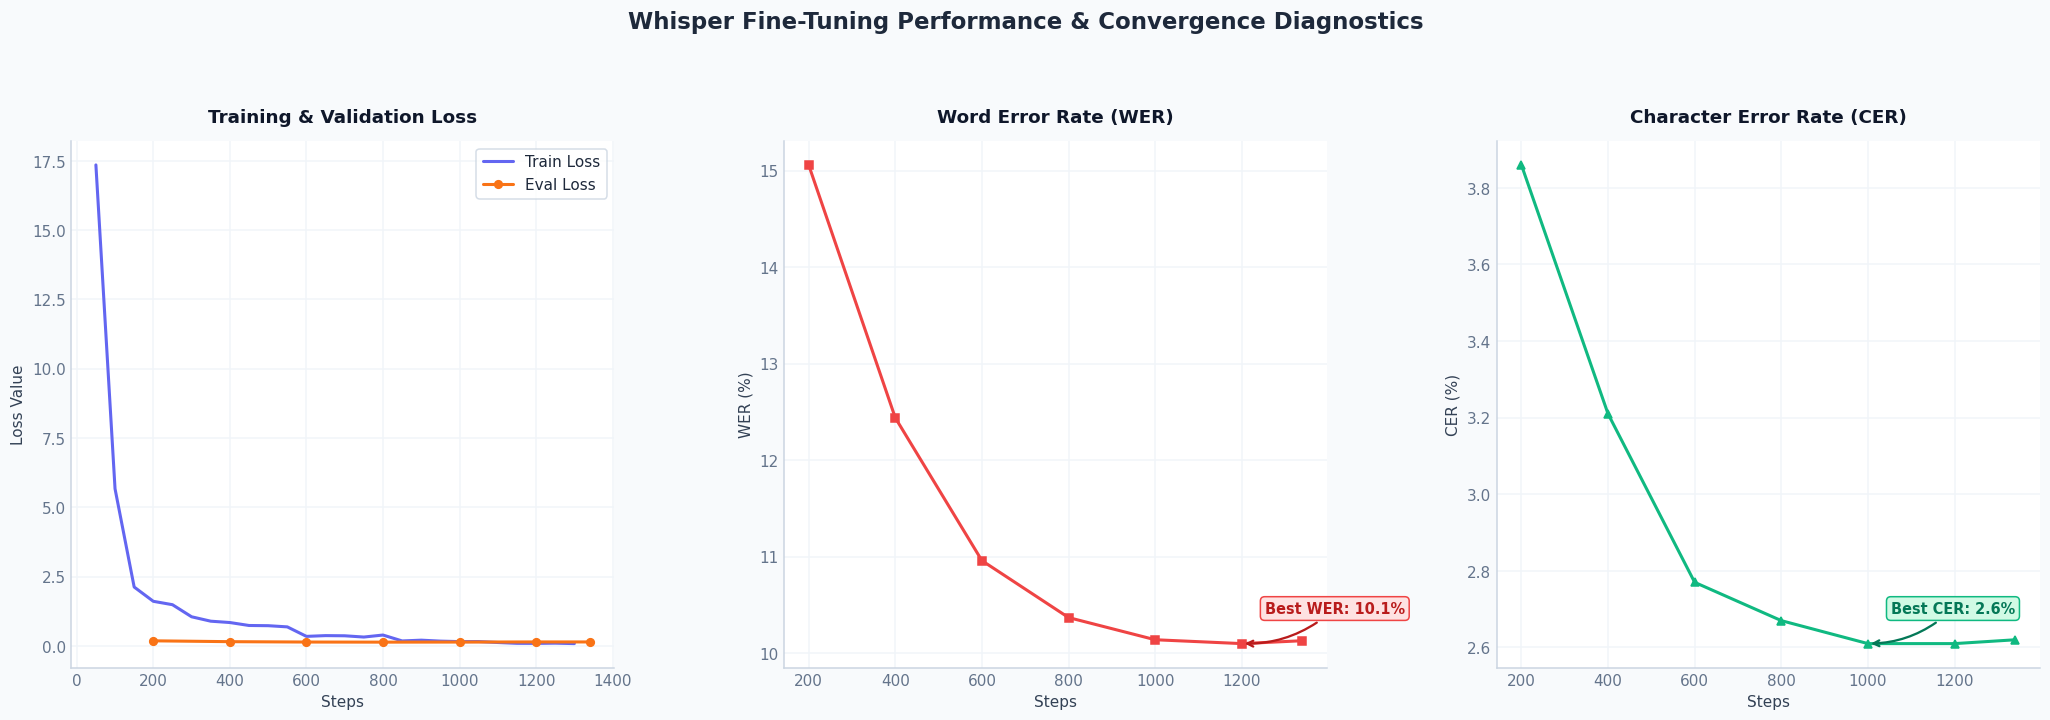

✅ Training history saved.


In [14]:
# ============================================================================
# SECTION 14: TRAINING HISTORY PLOT
# ============================================================================

log_history = trainer.state.log_history

train_steps = [e['step'] for e in log_history if 'loss' in e and 'eval_loss' not in e]
train_losses = [e['loss'] for e in log_history if 'loss' in e and 'eval_loss' not in e]

eval_steps_l = [e['step'] for e in log_history if 'eval_loss' in e]
eval_losses = [e['eval_loss'] for e in log_history if 'eval_loss' in e]
eval_wers = [e['eval_wer'] for e in log_history if 'eval_wer' in e]
eval_cers = [e['eval_cer'] for e in log_history if 'eval_cer' in e]

apply_premium_style()
fig, axes = plt.subplots(1, 3, figsize=(19, 6.5))

# 1. Loss Subplot
axes[0].plot(train_steps, train_losses, color='#6366f1', lw=2, label='Train Loss')
if eval_losses:
    axes[0].plot(eval_steps_l, eval_losses, color='#f97316', lw=2, marker='o', ms=5, label='Eval Loss')
axes[0].set_title('Training & Validation Loss', fontsize=12, fontweight='bold', color='#0f172a')
axes[0].set_xlabel('Steps', fontsize=10)
axes[0].set_ylabel('Loss Value', fontsize=10)
axes[0].legend(frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# 2. WER Subplot
if eval_wers:
    eval_steps_w = eval_steps_l[:len(eval_wers)]
    axes[1].plot(eval_steps_w, eval_wers, color='#ef4444', lw=2, marker='s', ms=5, label='Word Error Rate')
    best_i = np.argmin(eval_wers)
    axes[1].annotate(
        f'Best WER: {eval_wers[best_i]:.1f}%',
        xy=(eval_steps_w[best_i], eval_wers[best_i]),
        xytext=(15, 20), textcoords='offset points', fontsize=9.5,
        color='#b91c1c', fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.3", fc="#fee2e2", ec="#ef4444", lw=1),
        arrowprops=dict(arrowstyle='->', color='#b91c1c', lw=1.5, connectionstyle="arc3,rad=-0.2")
    )
axes[1].set_title('Word Error Rate (WER)', fontsize=12, fontweight='bold', color='#0f172a')
axes[1].set_xlabel('Steps', fontsize=10)
axes[1].set_ylabel('WER (%)', fontsize=10)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# 3. CER Subplot
if eval_cers:
    eval_steps_c = eval_steps_l[:len(eval_cers)]
    axes[2].plot(eval_steps_c, eval_cers, color='#10b981', lw=2, marker='^', ms=5, label='Character Error Rate')
    best_i = np.argmin(eval_cers)
    axes[2].annotate(
        f'Best CER: {eval_cers[best_i]:.1f}%',
        xy=(eval_steps_c[best_i], eval_cers[best_i]),
        xytext=(15, 20), textcoords='offset points', fontsize=9.5,
        color='#047857', fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.3", fc="#d1fae5", ec="#10b981", lw=1),
        arrowprops=dict(arrowstyle='->', color='#047857', lw=1.5, connectionstyle="arc3,rad=-0.2")
    )
axes[2].set_title('Character Error Rate (CER)', fontsize=12, fontweight='bold', color='#0f172a')
axes[2].set_xlabel('Steps', fontsize=10)
axes[2].set_ylabel('CER (%)', fontsize=10)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)

fig.suptitle('Whisper Fine-Tuning Performance & Convergence Diagnostics', fontsize=15, fontweight='bold', color='#1e293b', y=1.02)
plt.tight_layout(pad=2.0)
plt.savefig(f"{CONFIG['save_dir']}/training_history.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Training history saved.")


# 🏁 Section 15: Final Summary Dashboard
---
A high-level corporate summary containing all run specifications, platform, training hyperparameters, and final Word Error Rate metrics.


In [15]:
# SECTION 15: FINAL SUMMARY
# ============================================================================

print("\n" + "=" * 65)
print("  🏁  ARABIC ASR — PIPELINE COMPLETE")
print("=" * 65)

summary = [
    ("Platform", "Kaggle"),
    ("Model", CONFIG['model_name']),
    ("Dataset", CONFIG['dataset_name']),
    ("Train", f"{len(processed['train']):,}"),
    ("Validation", f"{len(processed['validation']):,}"),
    ("Test", f"{len(processed['test']):,}"),
    ("Epochs", CONFIG['epochs']),
    ("Effective batch", eff_batch),
    ("Learning rate", CONFIG['lr']),
    ("FP16", CONFIG['fp16']),
    ("Encoder frozen", FREEZE_ENCODER),
    ("Test WER", f"{wer_val}%"),
    ("Test CER", f"{cer_val}%"),
    ("Model path", LOCAL_EXPORT),
    ("ZIP", zip_path),
]

for label, value in summary:
    print(f"  {label:<20}: {value}")

print("=" * 65)
print("\n🎉 Done! All outputs in /kaggle/working/")



  🏁  ARABIC ASR — PIPELINE COMPLETE
  Platform            : Kaggle
  Model               : openai/whisper-small
  Dataset             : MBZUAI/ClArTTS
  Train               : 8,550
  Validation          : 950
  Test                : 205
  Epochs              : 5
  Effective batch     : 16
  Learning rate       : 1e-05
  FP16                : True
  Encoder frozen      : False
  Test WER            : 9.98%
  Test CER            : 2.73%
  Model path          : /kaggle/working/whisper-arabic-final
  ZIP                 : /kaggle/working/whisper-arabic-model.zip

🎉 Done! All outputs in /kaggle/working/
